# Practical Report 6 — Opening the Transformer


## Objective
Inspect pretrained encoder-only, decoder-only and encoder-decoder Transformers. Implement core attention equations in NumPy, visualize attention and positional encodings, compare inference strategies, and evaluate a pretrained sentiment model. No training or fine-tuning is performed.

**Models:** `distilbert-base-uncased-finetuned-sst-2-english`, `gpt2`, `t5-small`  
**Note:** The first run downloads public models and the IMDB sample, so an internet connection is required. CPU execution is supported, but model downloads and the full practical can take time.

## Setup and reproducibility
This cell installs the required libraries only if they are missing. If your notebook environment does not allow package installation, run `pip install transformers torch datasets matplotlib seaborn numpy pandas scikit-learn` in a terminal, then restart the kernel.

In [87]:
import sys, subprocess, importlib.util, warnings, time, math, random, re
packages = {
    "transformers": "transformers",
    "torch": "torch",
    "datasets": "datasets",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn"
}
missing = [pkg for mod, pkg in packages.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import (
    pipeline, AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
    AutoModelForCausalLM, T5ForConditionalGeneration, T5Tokenizer
)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = 0 if torch.cuda.is_available() else -1
TORCH_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", TORCH_DEVICE)

Python: 3.11.9
PyTorch: 2.14.0+cpu
Device: cpu


## Task 1 — Introduction, history, pipelines and tokenizer
**Objective:** Run a pretrained sentiment pipeline and inspect tokenization and model configuration.  
**Expected output:** Five sentiment predictions, a short timeline, token IDs/masks, and model anatomy.

### 1.1 First sentiment pipeline
A pipeline combines tokenization, the model's forward pass, and post-processing into one convenient call. The model is already fine-tuned for sentiment; this notebook does not train it.

In [88]:
sentiment_model_id = "distilbert-base-uncased-finetuned-sst-2-english"
sentiment_pipe = pipeline("sentiment-analysis", model=sentiment_model_id, device=DEVICE)
sentences = [
    "I absolutely loved this film and its performances.",
    "This was boring and a complete waste of time.",
    "The food was fresh and the service was excellent.",
    "I expected to dislike it, but it was surprisingly good.",
    "The movie was not bad, although it was not perfect."
]
for sentence, result in zip(sentences, sentiment_pipe(sentences, truncation=True)):
    print(f"{sentence}\n  {result['label']} (score={result['score']:.4f})")

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 330.94it/s]


I absolutely loved this film and its performances.
  POSITIVE (score=0.9999)
This was boring and a complete waste of time.
  NEGATIVE (score=0.9998)
The food was fresh and the service was excellent.
  POSITIVE (score=0.9999)
I expected to dislike it, but it was surprisingly good.
  POSITIVE (score=0.9998)
The movie was not bad, although it was not perfect.
  POSITIVE (score=0.9545)


### 1.2 History and 1.3 impact/disadvantages
Transformers process token representations in parallel, unlike recurrent models that pass information step by step. This makes training on sequences easier to parallelize and gives attention a direct way to connect distant tokens, although long sequences can be expensive.

In [89]:
history = pd.DataFrame([
    (2014-0, "2014–2015", "Sequence-to-sequence + attention (Bahdanau/Luong)", "Attention lets a decoder focus on relevant encoder states."),
    (2017, "2017", "Attention Is All You Need", "Introduced the Transformer architecture based on attention."),
    (2018, "2018", "BERT and GPT", "Popularized pretrained encoder and decoder language models."),
    (2019, "2019", "GPT-2, T5 and DistilBERT", "Expanded generation, text-to-text learning and model distillation."),
    (2020, "2020 onward", "Large language models and Vision Transformers", "Extended Transformer scaling and applications to images and many domains.")
], columns=["year_numeric", "Year", "Model or paper", "Why it mattered"]).drop(columns=["year_numeric"])
display(history)
print("Impact: translation, search, chat assistants, code completion, image models, protein-structure prediction.")
print("Disadvantages: quadratic self-attention cost with sequence length, context limits, compute/memory demands, data requirements, hallucinations, and opaque behaviour.")

,Year,Model or paper,Why it mattered
0,2014–2015,Sequence-to-sequence + attention (Bahdanau/Luong),Attention lets a decoder focus on relevant enc...
1,2017,Attention Is All You Need,Introduced the Transformer architecture based ...
2,2018,BERT and GPT,Popularized pretrained encoder and decoder lan...
3,2019,"GPT-2, T5 and DistilBERT","Expanded generation, text-to-text learning and..."
4,2020 onward,Large language models and Vision Transformers,Extended Transformer scaling and applications ...


Impact: translation, search, chat assistants, code completion, image models, protein-structure prediction.
Disadvantages: quadratic self-attention cost with sequence length, context limits, compute/memory demands, data requirements, hallucinations, and opaque behaviour.


### 1.4 Tokenizer in action

In [90]:
tokenizer = AutoTokenizer.from_pretrained(sentiment_model_id)
text = "Transformers are surprisingly easy to understand."
encoded = tokenizer(text)
print("Text:", text)
print("Tokens:", tokenizer.tokenize(text))
print("input_ids:", encoded["input_ids"])
print("attention_mask:", encoded["attention_mask"])
print("Tokens with special tokens:", tokenizer.convert_ids_to_tokens(encoded["input_ids"]))
print("[CLS] conventionally marks the start and [SEP] separates/ends segments in BERT-style tokenizers; subwords handle rare words without needing a vocabulary entry for every whole word.")
print("Subword example:", tokenizer.tokenize("unbelievably"))

Text: Transformers are surprisingly easy to understand.
Tokens: ['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']
input_ids: [101, 19081, 2024, 10889, 3733, 2000, 3305, 1012, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1]
Tokens with special tokens: ['[CLS]', 'transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.', '[SEP]']
[CLS] conventionally marks the start and [SEP] separates/ends segments in BERT-style tokenizers; subwords handle rare words without needing a vocabulary entry for every whole word.
Subword example: ['un', '##bel', '##ie', '##va', '##bly']


### 1.5 Batching and padding

In [91]:
batch = tokenizer(
    ["Transformers process tokens.", "Transformers can represent relationships between words in longer sentences."],
    padding=True, return_tensors="pt"
)
print("input_ids:\n", batch["input_ids"])
print("attention_mask:\n", batch["attention_mask"])
print("Mask meaning: 1 = real token; 0 = padding token.")

input_ids:
 tensor([[  101, 19081,  2832, 19204,  2015,  1012,   102,     0,     0,     0,
             0,     0],
        [  101, 19081,  2064,  5050,  6550,  2090,  2616,  1999,  2936, 11746,
          1012,   102]])
attention_mask:
 tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])
Mask meaning: 1 = real token; 0 = padding token.


### 1.6 Model anatomy at a glance

In [92]:
classifier = AutoModelForSequenceClassification.from_pretrained(sentiment_model_id)
cfg = classifier.config
config_table = pd.DataFrame([
    ("Transformer layers", getattr(cfg, "n_layers", getattr(cfg, "num_hidden_layers", "not exposed"))),
    ("Attention heads", getattr(cfg, "n_heads", getattr(cfg, "num_attention_heads", "not exposed"))),
    ("Hidden size", getattr(cfg, "dim", getattr(cfg, "hidden_size", "not exposed"))),
    ("Vocabulary size", cfg.vocab_size),
    ("Maximum position embeddings", getattr(cfg, "max_position_embeddings", getattr(cfg, "n_positions", "not exposed"))),
    ("Total parameters", sum(p.numel() for p in classifier.parameters()))
], columns=["Property", "Value"])
display(config_table)
print("First 15 parameter names:")
for name, _ in list(classifier.named_parameters())[:15]:
    print(name)

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 361.39it/s]


,Property,Value
0,Transformer layers,6
1,Attention heads,12
2,Hidden size,768
3,Vocabulary size,30522
4,Maximum position embeddings,512
5,Total parameters,66955010


First 15 parameter names:
distilbert.embeddings.word_embeddings.weight
distilbert.embeddings.position_embeddings.weight
distilbert.embeddings.LayerNorm.weight
distilbert.embeddings.LayerNorm.bias
distilbert.transformer.layer.0.attention.q_lin.weight
distilbert.transformer.layer.0.attention.q_lin.bias
distilbert.transformer.layer.0.attention.k_lin.weight
distilbert.transformer.layer.0.attention.k_lin.bias
distilbert.transformer.layer.0.attention.v_lin.weight
distilbert.transformer.layer.0.attention.v_lin.bias
distilbert.transformer.layer.0.attention.out_lin.weight
distilbert.transformer.layer.0.attention.out_lin.bias
distilbert.transformer.layer.0.sa_layer_norm.weight
distilbert.transformer.layer.0.sa_layer_norm.bias
distilbert.transformer.layer.0.ffn.lin1.weight


## Task 2 — Self-attention and scaled dot-product attention
**Objective:** Implement attention equations from scratch and compare with Luong dot attention.  
**Expected output:** Intermediate shapes, attention heatmaps, scaling comparison, and order-blindness demonstration.

### 2.1 Self-attention idea
Each token produces a Query (what it seeks), Key (what it offers), and Value (information to pass on). Query–Key similarities become weights after softmax; the output is the weighted sum of Value vectors. All tokens can be processed in parallel.

X, Wq, Wk, Wv: (4, 8) (8, 8) (8, 8) (8, 8)
Q, K, V: (4, 8) (4, 8) (4, 8)
scores, weights, output: (4, 4) (4, 4) (4, 8)
Row sums: [1. 1. 1. 1.]


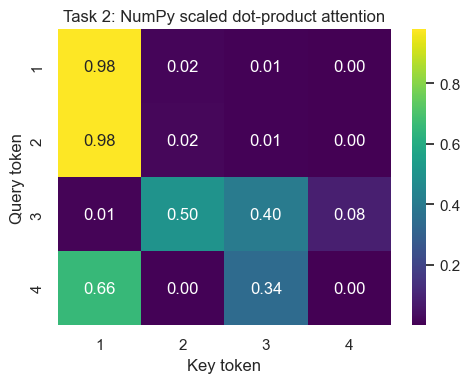

In [93]:
def stable_softmax(x, axis=-1):
    x = np.asarray(x, dtype=np.float64)
    x_shifted = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x_shifted)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

rng = np.random.default_rng(SEED)
d_model = 8
X = rng.normal(size=(4, d_model))
Wq, Wk, Wv = (rng.normal(size=(d_model, d_model)) for _ in range(3))
Q, K, V = X @ Wq, X @ Wk, X @ Wv
scores = Q @ K.T / np.sqrt(d_model)
weights = stable_softmax(scores, axis=-1)
attention_output = weights @ V
print("X, Wq, Wk, Wv:", X.shape, Wq.shape, Wk.shape, Wv.shape)
print("Q, K, V:", Q.shape, K.shape, V.shape)
print("scores, weights, output:", scores.shape, weights.shape, attention_output.shape)
print("Row sums:", weights.sum(axis=1))
plt.figure(figsize=(5,4))
sns.heatmap(weights, annot=True, fmt=".2f", cmap="viridis", xticklabels=range(1,5), yticklabels=range(1,5))
plt.title("Task 2: NumPy scaled dot-product attention")
plt.xlabel("Key token"); plt.ylabel("Query token"); plt.tight_layout(); plt.show()

### 2.3 Why divide by square root of key dimension?

In [94]:
def scaling_experiment(dk, use_scaling, seed=42):
    r = np.random.default_rng(seed + dk + int(use_scaling))
    q = r.normal(size=(128, dk))
    k = r.normal(size=(128, dk))
    raw = q @ k.T
    scaled_scores = raw / np.sqrt(dk) if use_scaling else raw
    probs = stable_softmax(scaled_scores, axis=-1)
    entropy = -(probs * np.log(probs + 1e-12)).sum(axis=-1).mean()
    return probs.max(axis=1).mean(), entropy

rows = []
for dk in (4, 256):
    for scaled in (False, True):
        max_prob, entropy = scaling_experiment(dk, scaled)
        rows.append({"d_k": dk, "Scaling": "with 1/sqrt(d_k)" if scaled else "without scaling",
                     "Mean row max probability": max_prob, "Mean entropy": entropy})
display(pd.DataFrame(rows))
print("Scaling controls score magnitude and helps avoid an overly saturated softmax.")

,d_k,Scaling,Mean row max probability,Mean entropy
0,4,without scaling,0.172998,3.566125
1,4,with 1/sqrt(d_k),0.064640,4.434690
2,256,without scaling,0.842744,0.382908
3,256,with 1/sqrt(d_k),0.064843,4.370962


Scaling controls score magnitude and helps avoid an overly saturated softmax.


### 2.4 Luong dot attention and comparison

In [95]:
rng = np.random.default_rng(SEED)
encoder_states = rng.normal(size=(5, 8))
decoder_state = rng.normal(size=(8,))
luong_scores = encoder_states @ decoder_state
luong_weights = stable_softmax(luong_scores)
context = luong_weights @ encoder_states
print("Luong attention weights:", np.round(luong_weights, 4))
print("Context shape:", context.shape)
display(pd.DataFrame([
    ("Query/Key/Value", "Each token projects its own Q, K and V", "Decoder state scores encoder states; encoder states provide context"),
    ("Attended items", "Every token attends to tokens in the same sequence", "Decoder step attends over encoder states"),
    ("Requires RNN", "No", "Originally often used with recurrent encoder/decoder"),
    ("Parallelism", "All sequence positions can be processed together", "Decoder attention is computed per decoding step"),
    ("Typical location", "Transformer encoder or decoder self-attention", "Encoder-decoder alignment/context")
], columns=["Aspect", "Self-attention", "Luong dot attention"]))

Luong attention weights: [0.0632 0.1247 0.1915 0.5876 0.033 ]
Context shape: (8,)


,Aspect,Self-attention,Luong dot attention
0,Query/Key/Value,"Each token projects its own Q, K and V",Decoder state scores encoder states; encoder s...
1,Attended items,Every token attends to tokens in the same sequ...,Decoder step attends over encoder states
2,Requires RNN,No,Originally often used with recurrent encoder/d...
3,Parallelism,All sequence positions can be processed together,Decoder attention is computed per decoding step
4,Typical location,Transformer encoder or decoder self-attention,Encoder-decoder alignment/context


### 2.5 Attention is order-blind without positional information

In [96]:
perm = np.array([2, 0, 3, 1])
def self_attn(x):
    q, k, v = x @ Wq, x @ Wk, x @ Wv
    return stable_softmax(q @ k.T / np.sqrt(d_model)) @ v
original_out = self_attn(X)
shuffled_out = self_attn(X[perm])
print("Outputs follow the shuffled token rows:", np.allclose(shuffled_out, original_out[perm], atol=1e-8))

Outputs follow the shuffled token rows: True


### 2.6 Verify attention against DistilBERT

In [97]:
# Load eager attention so the model returns its attention matrices.
try:
    base_encoder = AutoModel.from_pretrained(
        sentiment_model_id, attn_implementation="eager"
    ).to(TORCH_DEVICE).eval()
except (TypeError, ValueError):
    base_encoder = AutoModel.from_pretrained(sentiment_model_id).to(TORCH_DEVICE).eval()

verify_text = "The animal did not cross the street because it was tired."
verify_inputs = tokenizer(verify_text, return_tensors="pt", truncation=True).to(TORCH_DEVICE)
with torch.no_grad():
    verify_out = base_encoder(**verify_inputs, output_attentions=True, output_hidden_states=True, return_dict=True)
print("Attention tensor shape:", tuple(verify_out.attentions[0].shape))
print("Hidden-state tensor shape:", tuple(verify_out.hidden_states[0].shape))
print("This output exposes the actual attention weights for inspection. Projection reconstruction is implementation-dependent; the returned matrix is the reference attention from the pretrained model.")

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 237.83it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.weight     | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Attention tensor shape: (1, 12, 14, 14)
Hidden-state tensor shape: (1, 14, 768)
This output exposes the actual attention weights for inspection. Projection reconstruction is implementation-dependent; the returned matrix is the reference attention from the pretrained model.


## Task 3 — Multi-head attention, positional encoding and layer normalization
**Objective:** Inspect attention heads, build positional encodings, and verify LayerNorm.  
**Expected output:** Head heatmaps/entropy, positional encoding heatmap, learned-position similarity, and normalization checks.

### 3.1 Multi-head attention

In [98]:
print("DistilBERT uses multiple attention heads so different heads can learn different token relationships; the head outputs are concatenated and mixed by an output projection.")

DistilBERT uses multiple attention heads so different heads can learn different token relationships; the head outputs are concatenated and mixed by an output projection.


### 3.2 Extract and plot real attention heads

Attention shapes: [torch.Size([1, 12, 15, 15]), torch.Size([1, 12, 15, 15]), torch.Size([1, 12, 15, 15]), torch.Size([1, 12, 15, 15]), torch.Size([1, 12, 15, 15]), torch.Size([1, 12, 15, 15])]


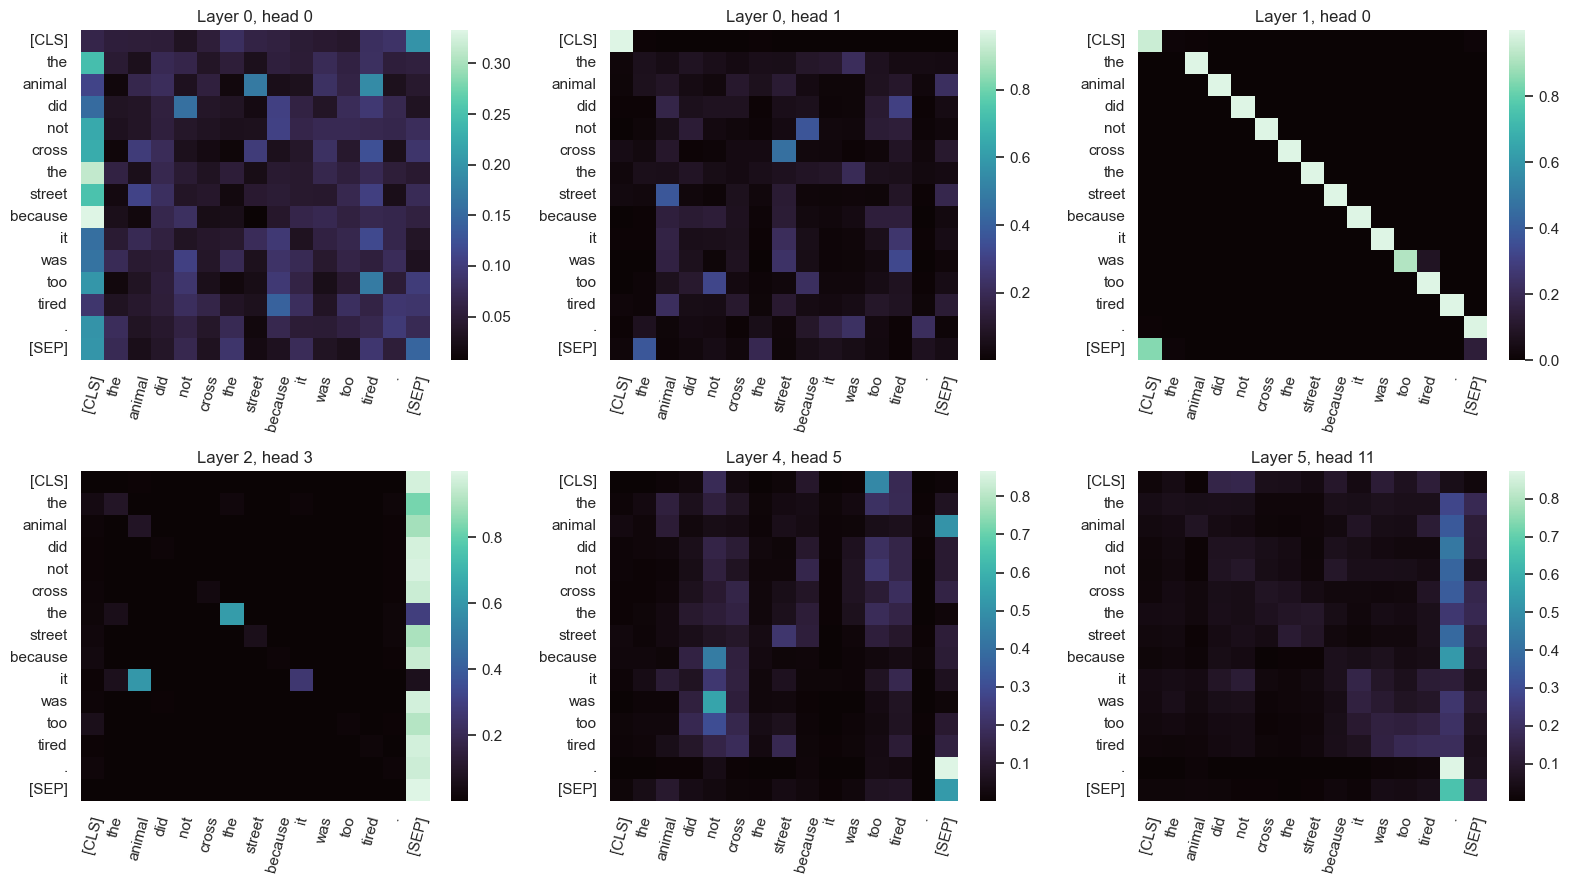

Inspect the token labels and heatmaps; individual heads can emphasize different relationships, but one sentence is not enough to generalize about a head.


In [99]:
head_text = "The animal did not cross the street because it was too tired."
head_inputs = tokenizer(head_text, return_tensors="pt", truncation=True).to(TORCH_DEVICE)
with torch.no_grad():
    head_out = base_encoder(**head_inputs, output_attentions=True, return_dict=True)
tokens = tokenizer.convert_ids_to_tokens(head_inputs["input_ids"][0].detach().cpu().tolist())
attns = [a[0].detach().cpu().numpy() for a in head_out.attentions]
print("Attention shapes:", [a.shape for a in head_out.attentions])
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
chosen = [(0,0), (0,1), (1,0), (2,3), (4,5), (5,11)]
for ax, (layer_i, head_i) in zip(axes.flat, chosen):
    layer_i = min(layer_i, len(attns)-1)
    head_i = min(head_i, attns[layer_i].shape[0]-1)
    sns.heatmap(attns[layer_i][head_i], ax=ax, cmap="mako", xticklabels=tokens, yticklabels=tokens)
    ax.set_title(f"Layer {layer_i}, head {head_i}")
    ax.tick_params(axis="x", rotation=75); ax.tick_params(axis="y", rotation=0)
plt.tight_layout(); plt.show()
print("Inspect the token labels and heatmaps; individual heads can emphasize different relationships, but one sentence is not enough to generalize about a head.")

### 3.3 Head diversity by attention entropy

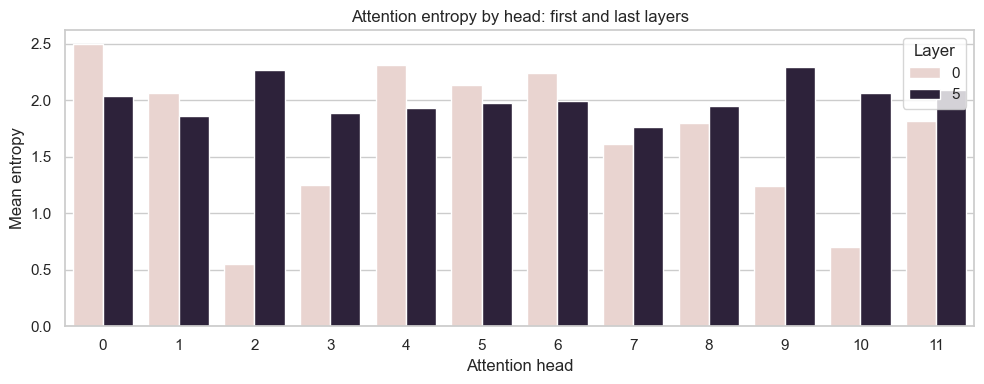

Entropy describes how concentrated or spread attention is for this particular input.


In [100]:
def attention_entropy(a):
    p = np.clip(a, 1e-12, 1.0)
    return -(p * np.log(p)).sum(axis=-1).mean(axis=-1)
layer_ids = [0, len(attns)-1]
entropy_rows = []
for li in layer_ids:
    for hi, val in enumerate(attention_entropy(attns[li])):
        entropy_rows.append({"Layer": li, "Head": hi, "Mean attention entropy": val})
entropy_df = pd.DataFrame(entropy_rows)
plt.figure(figsize=(10,4))
sns.barplot(data=entropy_df, x="Head", y="Mean attention entropy", hue="Layer")
plt.title("Attention entropy by head: first and last layers")
plt.xlabel("Attention head"); plt.ylabel("Mean entropy"); plt.tight_layout(); plt.show()
print("Entropy describes how concentrated or spread attention is for this particular input.")

### 3.4 Sinusoidal positional encoding from scratch

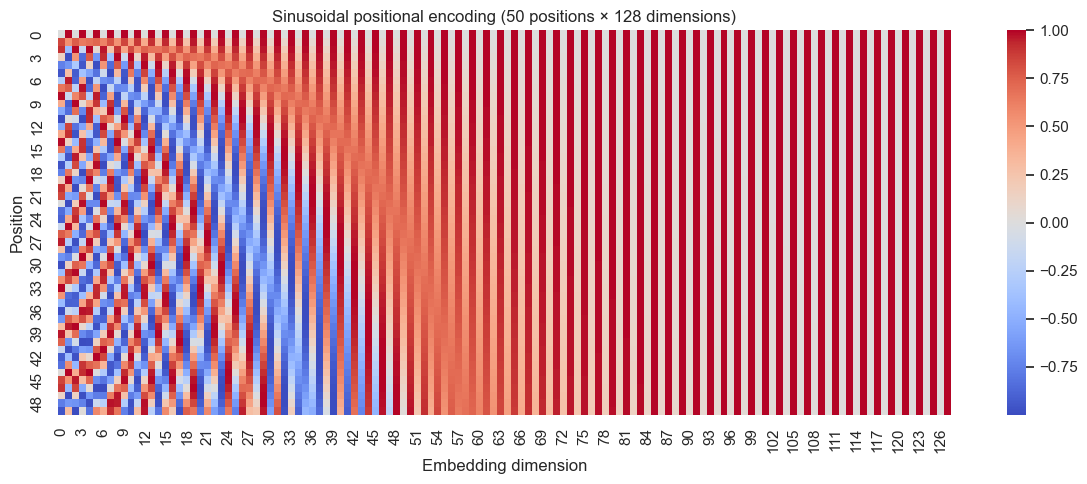

In [101]:
def sinusoidal_positional_encoding(max_positions=50, d_model=128):
    pos = np.arange(max_positions)[:, None]
    dim = np.arange(d_model)[None, :]
    angle_rates = 1 / np.power(10000, (2 * (dim // 2)) / d_model)
    angles = pos * angle_rates
    pe = np.zeros((max_positions, d_model))
    pe[:, 0::2] = np.sin(angles[:, 0::2])
    pe[:, 1::2] = np.cos(angles[:, 1::2])
    return pe
PE = sinusoidal_positional_encoding()
plt.figure(figsize=(12,5))
sns.heatmap(PE, cmap="coolwarm", center=0)
plt.title("Sinusoidal positional encoding (50 positions × 128 dimensions)")
plt.xlabel("Embedding dimension"); plt.ylabel("Position"); plt.tight_layout(); plt.show()

### 3.5 Same word at different positions

In [102]:
rng = np.random.default_rng(SEED)
word = rng.normal(size=128)
v3, v20 = word + PE[3], word + PE[20]
cos = lambda a,b: float(np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b)+1e-12))
print("Cosine similarity without positional encoding:", cos(word, word))
print("Cosine similarity at positions 3 and 20:", cos(v3, v20))

Cosine similarity without positional encoding: 0.9999999999999878
Cosine similarity at positions 3 and 20: 0.8260652109464257


### 3.6 Learned positional embeddings in DistilBERT

Position embedding shape: (512, 768)


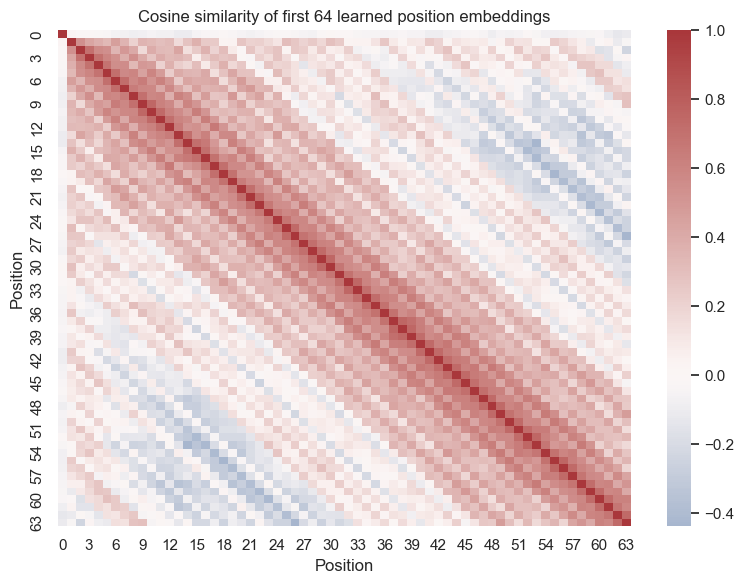

DistilBERT has a finite learned position table; T5 uses relative position biases instead.


In [103]:
pos_weight = base_encoder.embeddings.position_embeddings.weight.detach().cpu().numpy()
print("Position embedding shape:", pos_weight.shape)
first_positions = pos_weight[:64]
norms = np.linalg.norm(first_positions, axis=1, keepdims=True)
normalized = first_positions / np.maximum(norms, 1e-12)
pos_sim = normalized @ normalized.T
plt.figure(figsize=(8,6))
sns.heatmap(pos_sim, cmap="vlag", center=0)
plt.title("Cosine similarity of first 64 learned position embeddings")
plt.xlabel("Position"); plt.ylabel("Position"); plt.tight_layout(); plt.show()
print("DistilBERT has a finite learned position table; T5 uses relative position biases instead.")

### 3.7 and 3.8 LayerNorm versus BatchNorm

In [104]:
rng = np.random.default_rng(SEED)
arr = rng.normal(size=(4,8)).astype(np.float32)
eps = 1e-5
mean = arr.mean(axis=-1, keepdims=True)
var = arr.var(axis=-1, keepdims=True)
layer_norm_np = (arr - mean) / np.sqrt(var + eps)
torch_ln = torch.nn.LayerNorm(8, elementwise_affine=False)
layer_norm_torch = torch_ln(torch.tensor(arr)).numpy()
print("NumPy LayerNorm per-token means:", layer_norm_np.mean(axis=1).round(6))
print("NumPy LayerNorm per-token std:", layer_norm_np.std(axis=1).round(4))
print("Matches torch.nn.LayerNorm:", np.allclose(layer_norm_np, layer_norm_torch, atol=1e-5))
# Batch normalization across the token/batch axis, separately for each feature
bn = (arr - arr.mean(axis=0, keepdims=True)) / np.sqrt(arr.var(axis=0, keepdims=True) + eps)
print("BatchNorm feature means:", bn.mean(axis=0).round(5))
print("BatchNorm per-token means (not generally zero):", bn.mean(axis=1).round(4))
print("LayerNorm normalizes features within each token and is independent of other examples; BatchNorm normalizes each feature across a batch and depends on batch statistics.")
ln_module = base_encoder.embeddings.LayerNorm
print("Embedding LayerNorm gamma shape:", tuple(ln_module.weight.shape), "beta shape:", tuple(ln_module.bias.shape))

NumPy LayerNorm per-token means: [0. 0. 0. 0.]
NumPy LayerNorm per-token std: [1. 1. 1. 1.]
Matches torch.nn.LayerNorm: True
BatchNorm feature means: [-0. -0.  0.  0. -0.  0.  0. -0.]
BatchNorm per-token means (not generally zero): [-0.3335  0.0807  0.099   0.1538]
LayerNorm normalizes features within each token and is independent of other examples; BatchNorm normalizes each feature across a batch and depends on batch statistics.
Embedding LayerNorm gamma shape: (768,) beta shape: (768,)


## Task 4 — Transformer encoder architecture and masked self-attention
**Objective:** Inspect encoder modules and contrast bidirectional attention with causal masking.  
**Expected output:** Module/parameter summaries, fill-mask predictions, and attention mask heatmaps.

### 4.1–4.3 Encoder structure and parameter groups

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

,Component,Parameters,Share (%)
0,embeddings,23835648,35.599499
1,attention,14174208,21.169750
2,feed-forward,28334592,42.318853
3,layer norms,18432,0.027529
4,classification head,592130,0.884370
5,other,0,0.000000


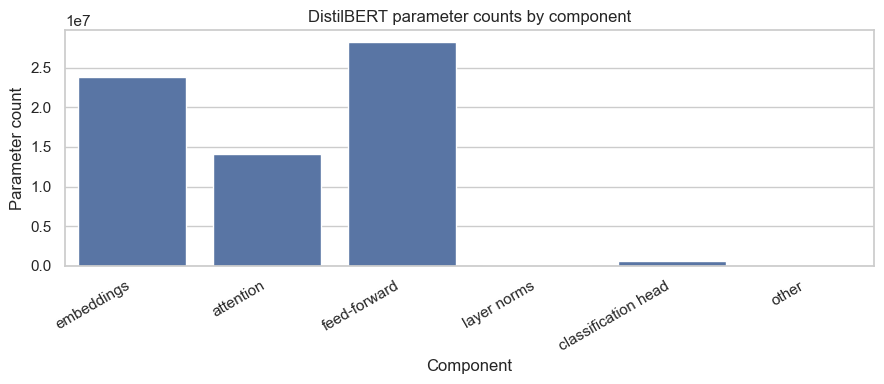

In [105]:
print(base_encoder)
print("Encoder: embeddings + stacked blocks; each block contains multi-head self-attention, residual/normalization, and feed-forward layers.")
param_groups = {"embeddings": 0, "attention": 0, "feed-forward": 0, "layer norms": 0, "classification head": 0, "other": 0}
for name, param in classifier.named_parameters():
    n = param.numel()
    lname = name.lower()
    if "embedding" in lname: group = "embeddings"
    elif any(x in lname for x in ["q_lin","k_lin","v_lin","out_lin","attention"]): group = "attention"
    elif any(x in lname for x in ["lin1","lin2","ffn","feed_forward"]): group = "feed-forward"
    elif "layernorm" in lname or "layer_norm" in lname: group = "layer norms"
    elif "classifier" in lname or "pre_classifier" in lname: group = "classification head"
    else: group = "other"
    param_groups[group] += n
param_df = pd.DataFrame([{"Component": k, "Parameters": v, "Share (%)": 100*v/sum(param_groups.values())} for k,v in param_groups.items()])
display(param_df)
plt.figure(figsize=(9,4))
sns.barplot(data=param_df, x="Component", y="Parameters")
plt.title("DistilBERT parameter counts by component"); plt.xticks(rotation=30, ha="right")
plt.ylabel("Parameter count"); plt.tight_layout(); plt.show()

### 4.4 Fill-mask pipeline

In [106]:
fill_pipe = pipeline("fill-mask", model="distilbert-base-uncased", device=DEVICE)
mask_sentences = [
    "The capital of France is [MASK].",
    "She drank a cup of [MASK] in the morning.",
    "A dog is a friendly [MASK]."
]
for s in mask_sentences:
    print("\n", s)
    for result in fill_pipe(s, top_k=3):
        print(f"  {result['token_str'].strip():<15} score={result['score']:.4f}")

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 303.97it/s]



 The capital of France is [MASK].
  marseille       score=0.1427
  nantes          score=0.0902
  toulouse        score=0.0881

 She drank a cup of [MASK] in the morning.
  coffee          score=0.3584
  tea             score=0.3214
  wine            score=0.0519

 A dog is a friendly [MASK].
  animal          score=0.3322
  dog             score=0.2487
  pet             score=0.0560


### 4.5 Bidirectional attention heatmap

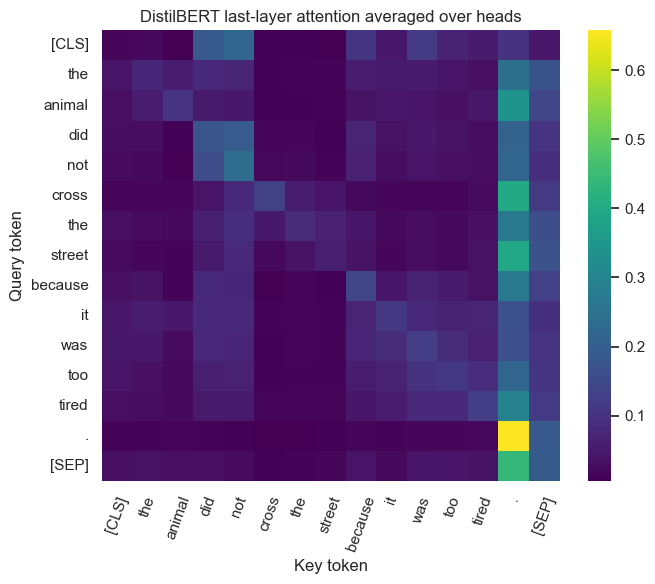

In [107]:
last_attn = attns[-1].mean(axis=0)
plt.figure(figsize=(7,6))
sns.heatmap(last_attn, cmap="viridis", xticklabels=tokens, yticklabels=tokens)
plt.title("DistilBERT last-layer attention averaged over heads")
plt.xlabel("Key token"); plt.ylabel("Query token"); plt.xticks(rotation=70); plt.tight_layout(); plt.show()

### 4.6 Causal mask from scratch

Causal attention matrix:
 [[1.    0.    0.    0.    0.    0.   ]
 [0.609 0.391 0.    0.    0.    0.   ]
 [0.186 0.537 0.278 0.    0.    0.   ]
 [0.513 0.203 0.177 0.108 0.    0.   ]
 [0.108 0.117 0.283 0.24  0.251 0.   ]
 [0.561 0.044 0.04  0.029 0.122 0.204]]
Rows sum to 1: [1. 1. 1. 1. 1. 1.]
Maximum above diagonal: 0.0


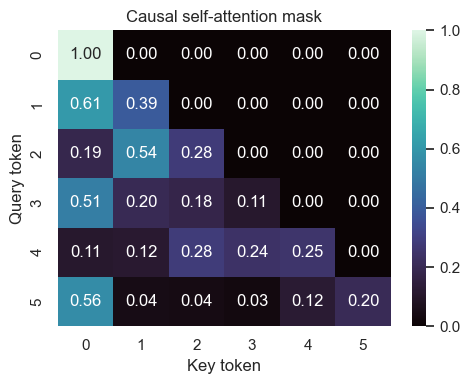

In [108]:
n_tokens = 6
rng = np.random.default_rng(SEED)
causal_scores = rng.normal(size=(n_tokens, n_tokens))
causal_mask = np.triu(np.full((n_tokens, n_tokens), -np.inf), k=1)
causal_weights = stable_softmax(causal_scores + causal_mask)
print("Causal attention matrix:\n", np.round(causal_weights, 3))
print("Rows sum to 1:", causal_weights.sum(axis=1))
print("Maximum above diagonal:", np.triu(causal_weights, k=1).max())
plt.figure(figsize=(5,4))
sns.heatmap(causal_weights, annot=True, fmt=".2f", cmap="mako")
plt.title("Causal self-attention mask"); plt.xlabel("Key token"); plt.ylabel("Query token"); plt.tight_layout(); plt.show()

### 4.7 Causal mask in GPT-2

Loading weights: 100%|██████████| 148/148 [00:01<00:00, 78.71it/s]


Maximum above-diagonal attention: 0.0


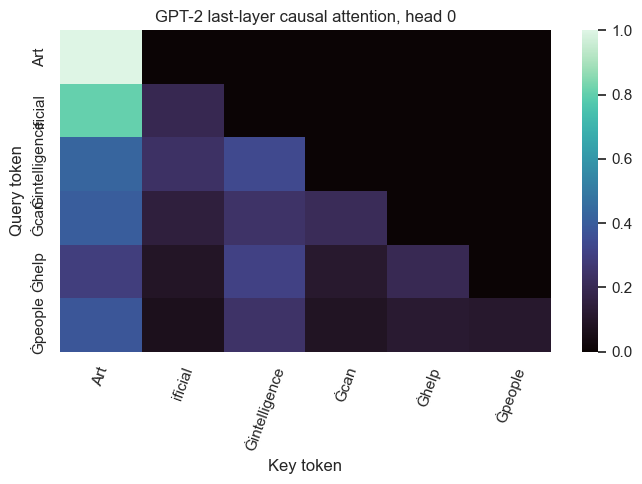

In [109]:
gpt2_id = "gpt2"
gpt2_tokenizer = AutoTokenizer.from_pretrained(gpt2_id)
if gpt2_tokenizer.pad_token is None:
    gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token
gpt2 = AutoModelForCausalLM.from_pretrained(gpt2_id, attn_implementation="eager").to(TORCH_DEVICE).eval()
gpt2_text = "Artificial intelligence can help people"
gpt2_inputs = gpt2_tokenizer(gpt2_text, return_tensors="pt").to(TORCH_DEVICE)
with torch.no_grad():
    gpt2_out = gpt2(**gpt2_inputs, output_attentions=True, return_dict=True)
gpt_attn = gpt2_out.attentions[-1][0,0].detach().cpu().numpy()
gpt_tokens = gpt2_tokenizer.convert_ids_to_tokens(gpt2_inputs["input_ids"][0].detach().cpu().tolist())
print("Maximum above-diagonal attention:", np.triu(gpt_attn, k=1).max())
plt.figure(figsize=(7,5))
sns.heatmap(gpt_attn, cmap="mako", xticklabels=gpt_tokens, yticklabels=gpt_tokens)
plt.title("GPT-2 last-layer causal attention, head 0")
plt.xlabel("Key token"); plt.ylabel("Query token"); plt.xticks(rotation=70); plt.tight_layout(); plt.show()

### 4.8 Padding mask versus causal mask

In [110]:
pad_batch = gpt2_tokenizer(["Short input.", "This is a longer input with more tokens."], padding=True, return_tensors="pt").to(TORCH_DEVICE)
print("Input IDs:\n", pad_batch["input_ids"])
print("Attention mask:\n", pad_batch["attention_mask"])
print("Padding mask ignores padded input positions; causal mask prevents a token from looking at future tokens. Encoder models commonly use padding masks; autoregressive decoders use causal masks and may also use padding masks.")

Input IDs:
 tensor([[16438,  5128,    13, 50256, 50256, 50256, 50256, 50256, 50256],
        [ 1212,   318,   257,  2392,  5128,   351,   517, 16326,    13]])
Attention mask:
 tensor([[1, 1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1]])
Padding mask ignores padded input positions; causal mask prevents a token from looking at future tokens. Encoder models commonly use padding masks; autoregressive decoders use causal masks and may also use padding masks.


## Task 5 — Cross-attention, decoder architecture and inference
**Objective:** Use T5 for translation/summarization and GPT-2 for autoregressive decoding.  
**Expected output:** Translation and summary, cross-attention plot, decoding comparison, cache timing.

### 5.1–5.3 Decoder architecture and translation

In [111]:

import torch
from transformers import T5Tokenizer, T5ForConditionalGeneration

# Load pretrained T5 model
t5_id = "t5-small"

t5_tokenizer = T5Tokenizer.from_pretrained(t5_id)

t5 = T5ForConditionalGeneration.from_pretrained(
    t5_id,
    attn_implementation="eager"
).to(TORCH_DEVICE).eval()

# English sentences
translation_sentences = [
    "The house is small.",
    "Transformers can process language in parallel.",
    "I enjoy learning about deep learning."
]

# Translate using T5 directly
for sentence in translation_sentences:
    input_text = "translate English to French: " + sentence

    inputs = t5_tokenizer(
        input_text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(TORCH_DEVICE)

    with torch.no_grad():
        outputs = t5.generate(
            **inputs,
            max_new_tokens=64,
            do_sample=False
        )

    translation = t5_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    print("English:", sentence)
    print("French:", translation)
    print("-" * 50)


Loading weights: 100%|██████████| 131/131 [00:00<00:00, 208.19it/s]


English: The house is small.
French: La maison est petite.
--------------------------------------------------
English: Transformers can process language in parallel.
French: Les transformateurs peuvent traiter le langage en parallèle.
--------------------------------------------------
English: I enjoy learning about deep learning.
French: Je me réjouis d'apprendre à l'apprentissage approfondi.
--------------------------------------------------


### 5.3 Summarization

In [112]:

import torch

paragraph = (
    "Researchers and engineers use machine learning systems to process large amounts of text, identify patterns, "
    "and support people with tasks such as translation, search, and summarization. Transformer models use attention "
    "to connect information across a sequence. Their performance depends on training data, model design, and the "
    "length of the input. These systems can be useful, but they may produce incorrect details and can require "
    "substantial computing resources. Careful evaluation is important before deploying them in high-impact settings."
)

# Prepare input for T5 summarization
input_text = "summarize: " + paragraph

inputs = t5_tokenizer(
    input_text,
    return_tensors="pt",
    truncation=True,
    max_length=512
).to(TORCH_DEVICE)

# Generate summary without using the removed pipeline
with torch.no_grad():
    summary_ids = t5.generate(
        **inputs,
        max_new_tokens=60,
        min_new_tokens=20,
        do_sample=False
    )

summary = t5_tokenizer.decode(
    summary_ids[0],
    skip_special_tokens=True
)

print("Input word count:", len(paragraph.split()))
print("Summary word count:", len(summary.split()))
print("Summary:", summary)


Input word count: 77
Summary word count: 28
Summary: researchers and engineers use machine learning systems to process large amounts of text. they can identify patterns and support people with tasks such as translation, search, and summarization.


### 5.4 Extract and plot cross-attention

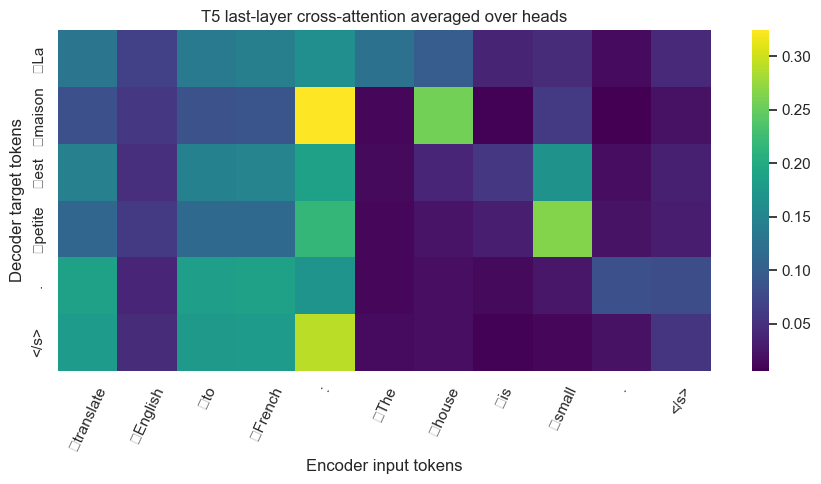

Cross-attention queries come from decoder states; keys and values come from encoder output.


In [113]:
source_text = "translate English to French: The house is small."
target_text = "La maison est petite."
src = t5_tokenizer(source_text, return_tensors="pt").to(TORCH_DEVICE)
labels = t5_tokenizer(target_text, return_tensors="pt").input_ids.to(TORCH_DEVICE)
with torch.no_grad():
    t5_out = t5(input_ids=src["input_ids"], attention_mask=src["attention_mask"],
                labels=labels, output_attentions=True, return_dict=True)
cross = t5_out.cross_attentions[-1][0].mean(dim=0).detach().cpu().numpy()
src_tokens = t5_tokenizer.convert_ids_to_tokens(src["input_ids"][0].detach().cpu().tolist())
tgt_tokens = t5_tokenizer.convert_ids_to_tokens(labels[0].detach().cpu().tolist())
plt.figure(figsize=(9,5))
sns.heatmap(cross, cmap="viridis", xticklabels=src_tokens, yticklabels=tgt_tokens)
plt.title("T5 last-layer cross-attention averaged over heads")
plt.xlabel("Encoder input tokens"); plt.ylabel("Decoder target tokens")
plt.xticks(rotation=65); plt.tight_layout(); plt.show()
print("Cross-attention queries come from decoder states; keys and values come from encoder output.")

### 5.5 Manual greedy decoding versus generate

In [114]:
prompt = "Artificial intelligence will"
prompt_ids = gpt2_tokenizer(prompt, return_tensors="pt").input_ids.to(TORCH_DEVICE)
manual_ids = prompt_ids.clone()
with torch.no_grad():
    for _ in range(20):
        logits = gpt2(input_ids=manual_ids).logits[:, -1, :]
        next_id = torch.argmax(logits, dim=-1, keepdim=True)
        manual_ids = torch.cat([manual_ids, next_id], dim=-1)
    generated_ids = gpt2.generate(prompt_ids, max_new_tokens=20, do_sample=False, pad_token_id=gpt2_tokenizer.eos_token_id)
manual_text = gpt2_tokenizer.decode(manual_ids[0], skip_special_tokens=True)
generated_text = gpt2_tokenizer.decode(generated_ids[0], skip_special_tokens=True)
print("Manual:", manual_text)
print("generate:", generated_text)
print("Identical token sequences:", torch.equal(manual_ids, generated_ids))

Manual: Artificial intelligence will be able to do things like search for and find people, and to do things like find out who
generate: Artificial intelligence will be able to do things like search for and find people, and to do things like find out who
Identical token sequences: True


### 5.6 Decoding strategies

In [115]:
def generate_text(seed, **kwargs):
    torch.manual_seed(seed)
    with torch.no_grad():
        ids = gpt2.generate(
            prompt_ids, max_new_tokens=40, pad_token_id=gpt2_tokenizer.eos_token_id,
            **kwargs
        )
    return gpt2_tokenizer.decode(ids[0], skip_special_tokens=True)

decoding_rows = [
    ("Greedy", generate_text(42, do_sample=False, num_beams=1)),
    ("Beam search (5)", generate_text(42, do_sample=False, num_beams=5, early_stopping=True)),
    ("Sampling temperature=0.7, seed=42", generate_text(42, do_sample=True, temperature=0.7)),
    ("Sampling temperature=0.7, seed=7", generate_text(7, do_sample=True, temperature=0.7)),
    ("Sampling temperature=1.5, seed=42", generate_text(42, do_sample=True, temperature=1.5)),
    ("Sampling temperature=1.5, seed=7", generate_text(7, do_sample=True, temperature=1.5)),
    ("top-k=50, top-p=0.9", generate_text(42, do_sample=True, top_k=50, top_p=0.9, temperature=1.0))
]
display(pd.DataFrame(decoding_rows, columns=["Strategy", "Output"]))
print("Higher temperature generally increases randomness; top-k and top-p restrict the candidate-token set.")

,Strategy,Output
0,Greedy,Artificial intelligence will be able to do thi...
1,Beam search (5),Artificial intelligence will be the next big t...
2,"Sampling temperature=0.7, seed=42",Artificial intelligence will be used to create...
3,"Sampling temperature=0.7, seed=7",Artificial intelligence will only be able to f...
4,"Sampling temperature=1.5, seed=42",Artificial intelligence will continue to expan...
5,"Sampling temperature=1.5, seed=7",Artificial intelligence will only reach some a...
6,"top-k=50, top-p=0.9",Artificial intelligence will continue to expan...


Higher temperature generally increases randomness; top-k and top-p restrict the candidate-token set.


### 5.7 KV-cache speed-up

In [116]:
def time_generation(use_cache, repeats=3):
    durations = []
    for _ in range(repeats):
        start = time.perf_counter()
        with torch.no_grad():
            _ = gpt2.generate(prompt_ids, max_new_tokens=100, do_sample=False,
                              use_cache=use_cache, pad_token_id=gpt2_tokenizer.eos_token_id)
        durations.append(time.perf_counter() - start)
    return float(np.mean(durations)), durations

cache_time, cache_runs = time_generation(True)
no_cache_time, no_cache_runs = time_generation(False)
print("use_cache=True average seconds:", round(cache_time, 3), cache_runs)
print("use_cache=False average seconds:", round(no_cache_time, 3), no_cache_runs)
print("Speed-up (no-cache / cache):", round(no_cache_time / max(cache_time, 1e-12), 2), "x")

use_cache=True average seconds: 8.757 [9.941509100026451, 7.95365049992688, 8.376325099961832]
use_cache=False average seconds: 25.243 [24.63145240000449, 24.199450199957937, 26.89834760001395]
Speed-up (no-cache / cache): 2.88 x


### 5.8 Model-family comparison

In [117]:
display(pd.DataFrame([
    ("DistilBERT", "Encoder-only", "Bidirectional self-attention", "No", "Learned absolute positions", "Sentiment, fill-mask", sentiment_model_id),
    ("GPT-2", "Decoder-only", "Causal self-attention", "Yes", "Learned absolute positions", "Autoregressive text generation", "gpt2"),
    ("T5-small", "Encoder-decoder", "Encoder self-attention + decoder causal self-attention + cross-attention", "Yes", "Relative position bias", "Translation, summarization", "t5-small")
], columns=["Model", "Family", "Attention types", "Can generate?", "Position scheme", "Typical tasks", "Exact model ID"]))

,Model,Family,Attention types,Can generate?,Position scheme,Typical tasks,Exact model ID
0,DistilBERT,Encoder-only,Bidirectional self-attention,No,Learned absolute positions,"Sentiment, fill-mask",distilbert-base-uncased-finetuned-sst-2-english
1,GPT-2,Decoder-only,Causal self-attention,Yes,Learned absolute positions,Autoregressive text generation,gpt2
2,T5-small,Encoder-decoder,Encoder self-attention + decoder causal self-a...,Yes,Relative position bias,"Translation, summarization",t5-small


## Task 6 — Mini application, evaluation and disadvantages in practice
**Objective:** Evaluate pretrained sentiment classification on 200 IMDB reviews, measure truncation/runtime effects, test factual generation, and build a text toolkit.  
**Expected output:** Evaluation metrics, confusion matrix, performance plots, hallucination checks, and a DataFrame of toolkit outputs.

### 6.1 Evaluate sentiment model on 200 IMDB reviews

,max_length,accuracy,precision,recall,f1,seconds
0,512,0.87,0.8889,0.8333,0.8602,162.1412


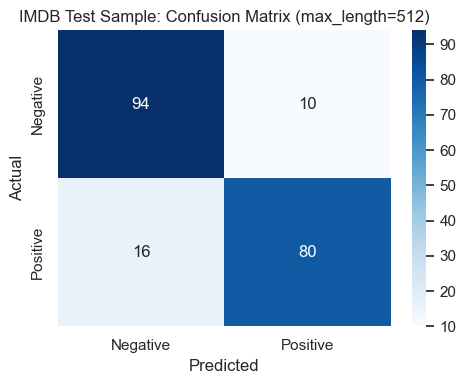

In [118]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Load and select 200 IMDB test reviews
imdb = load_dataset(
    "stanfordnlp/imdb",
    split="test"
).shuffle(seed=SEED).select(range(200))

reviews = [str(x) for x in imdb["text"]]
true_labels = np.asarray(imdb["label"], dtype=int)

def evaluate_reviews(max_length=512):
    start = time.perf_counter()

    preds = sentiment_pipe(
        reviews,
        batch_size=16,
        truncation=True,
        max_length=max_length
    )

    elapsed = time.perf_counter() - start

    pred_labels = np.array([
        1 if p["label"].upper() in ["POSITIVE", "LABEL_1"] else 0
        for p in preds
    ])

    metrics = {
        "max_length": max_length,
        "accuracy": accuracy_score(true_labels, pred_labels),
        "precision": precision_score(
            true_labels, pred_labels, zero_division=0
        ),
        "recall": recall_score(
            true_labels, pred_labels, zero_division=0
        ),
        "f1": f1_score(
            true_labels, pred_labels, zero_division=0
        ),
        "seconds": elapsed
    }

    return metrics, pred_labels

metrics_512, preds_512 = evaluate_reviews(512)

display(pd.DataFrame([metrics_512]).round(4))

cm = confusion_matrix(true_labels, preds_512)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.title("IMDB Test Sample: Confusion Matrix (max_length=512)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


### 6.2 Effect of truncation length

,max_length,accuracy,precision,recall,f1,seconds
0,64,0.750,0.767442,0.687500,0.725275,20.159056
1,128,0.775,0.757576,0.781250,0.769231,35.346928
2,256,0.840,0.863636,0.791667,0.826087,62.711556
3,512,0.870,0.888889,0.833333,0.860215,120.148165


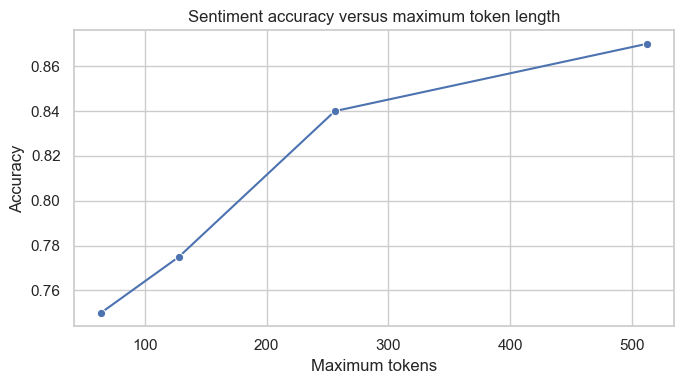

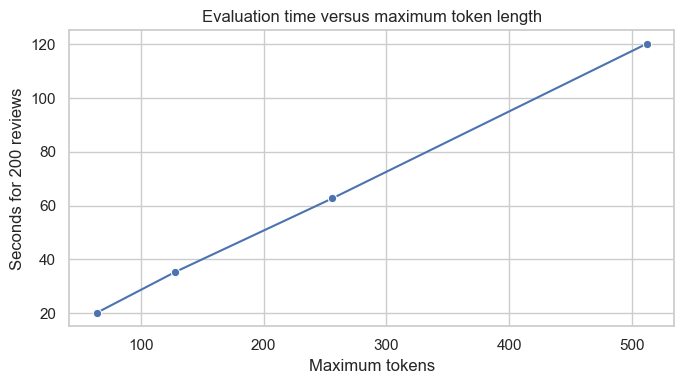

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (632 > 512). Running this sequence through the model will result in indexing errors


Reviews exceeding 512 tokens: 18 of 200
Accuracy difference (512 minus 64): 0.12


In [119]:
truncation_results = []
truncation_predictions = {}
for length in [64, 128, 256, 512]:
    result, pred = evaluate_reviews(length)
    truncation_results.append(result)
    truncation_predictions[length] = pred
trunc_df = pd.DataFrame(truncation_results)
display(trunc_df)
plt.figure(figsize=(7,4))
sns.lineplot(data=trunc_df, x="max_length", y="accuracy", marker="o")
plt.title("Sentiment accuracy versus maximum token length")
plt.xlabel("Maximum tokens"); plt.ylabel("Accuracy"); plt.tight_layout(); plt.show()
plt.figure(figsize=(7,4))
sns.lineplot(data=trunc_df, x="max_length", y="seconds", marker="o")
plt.title("Evaluation time versus maximum token length")
plt.xlabel("Maximum tokens"); plt.ylabel("Seconds for 200 reviews"); plt.tight_layout(); plt.show()
review_lengths = [len(tokenizer(x, add_special_tokens=True, truncation=False)["input_ids"]) for x in reviews]
print("Reviews exceeding 512 tokens:", sum(n > 512 for n in review_lengths), "of", len(review_lengths))
print("Accuracy difference (512 minus 64):", round(float(trunc_df.loc[trunc_df.max_length==512, "accuracy"].iloc[0] - trunc_df.loc[trunc_df.max_length==64, "accuracy"].iloc[0]), 4))

### 6.3 Cost grows with sequence length

,Requested length,Actual tokens,Mean forward seconds
0,32,32,0.111824
1,64,64,0.222306
2,128,128,0.193323
3,256,256,0.451623
4,512,512,0.716828


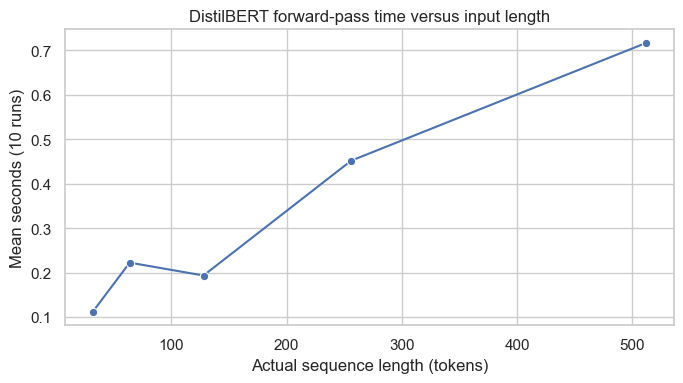

Self-attention's attention matrix scales quadratically with sequence length; measured CPU timings can differ due to overhead and hardware.


In [120]:
length_times = []
sample_text = "Transformers compare token representations using attention. "
for length in [32, 64, 128, 256, 512]:
    inputs = tokenizer(sample_text * (length // 6 + 2), return_tensors="pt", truncation=True, max_length=length).to(TORCH_DEVICE)
    actual_length = inputs["input_ids"].shape[1]
    with torch.no_grad():
        _ = base_encoder(**inputs)
    runs = []
    for _ in range(10):
        start = time.perf_counter()
        with torch.no_grad():
            _ = base_encoder(**inputs)
        runs.append(time.perf_counter() - start)
    length_times.append({"Requested length": length, "Actual tokens": actual_length, "Mean forward seconds": np.mean(runs)})
length_df = pd.DataFrame(length_times)
display(length_df)
plt.figure(figsize=(7,4))
sns.lineplot(data=length_df, x="Actual tokens", y="Mean forward seconds", marker="o")
plt.title("DistilBERT forward-pass time versus input length")
plt.xlabel("Actual sequence length (tokens)"); plt.ylabel("Mean seconds (10 runs)"); plt.tight_layout(); plt.show()
print("Self-attention's attention matrix scales quadratically with sequence length; measured CPU timings can differ due to overhead and hardware.")

### 6.4 Hallucination check

In [121]:
fact_prompts = [
    ("The capital of Australia is", "Canberra"),
    ("The author of the novel Pride and Prejudice is", "Jane Austen"),
    ("The inventor of the telephone was", "Alexander Graham Bell")
]
for fact_prompt, expected in fact_prompts:
    ids = gpt2_tokenizer(fact_prompt, return_tensors="pt").input_ids.to(TORCH_DEVICE)
    with torch.no_grad():
        out = gpt2.generate(ids, max_new_tokens=30, do_sample=False, pad_token_id=gpt2_tokenizer.eos_token_id)
    generated = gpt2_tokenizer.decode(out[0], skip_special_tokens=True)
    tail = generated[len(fact_prompt):].strip()
    print("\nPrompt:", fact_prompt)
    print("Expected fact:", expected)
    print("Generated continuation:", tail)
    print("Manual review required: mark Correct / Partly correct / Wrong after reading the output.")


Prompt: The capital of Australia is
Expected fact: Canberra
Generated continuation: the world's largest producer of coal, and the country's largest coal-fired power station.

The coal industry is also the world's largest
Manual review required: mark Correct / Partly correct / Wrong after reading the output.

Prompt: The author of the novel Pride and Prejudice is
Expected fact: Jane Austen
Generated continuation: a former member of the National Security Council.

The author of the novel is a former member of the National Security Council.

The author
Manual review required: mark Correct / Partly correct / Wrong after reading the output.

Prompt: The inventor of the telephone was
Expected fact: Alexander Graham Bell
Generated continuation: a man named John D. Rockefeller. He was a man who had been a member of the Rockefeller family for many years. He was a man who
Manual review required: mark Correct / Partly correct / Wrong after reading the output.


### 6.5 Build and test the mini text toolkit

In [122]:
def text_toolkit(text):
    if not isinstance(text, str) or not text.strip():
        return {"sentiment": "UNAVAILABLE", "sentiment_score": np.nan,
                "summary": "Please provide non-empty text.", "french_translation": ""}
    cleaned = text.strip()
    # Keep inputs manageable and make truncation explicit in the workflow.
    if len(cleaned) > 12000:
        cleaned = cleaned[:12000]
        note = "Input was shortened to 12,000 characters before processing."
    else:
        note = ""
    try:
        sentiment = sentiment_pipe(cleaned, truncation=True, max_length=512)[0]
        summary_result = summary_pipe(cleaned, max_length=60, min_length=10, do_sample=False, truncation=True)[0]["summary_text"]
        translated = translation_pipe("translate English to French: " + summary_result, max_new_tokens=80)[0]["translation_text"]
        return {
            "sentiment": sentiment["label"],
            "sentiment_score": round(float(sentiment["score"]), 4),
            "summary": summary_result + ((" [" + note + "]") if note else ""),
            "french_translation": translated
        }
    except Exception as exc:
        return {"sentiment": "ERROR", "sentiment_score": np.nan,
                "summary": f"Processing failed: {type(exc).__name__}: {exc}",
                "french_translation": ""}

passages = [
    "The film had excellent acting, a thoughtful story, and a satisfying ending. I would recommend it to friends.",
    "A new city programme will improve public transport by adding electric buses, updating routes, and publishing arrival information online. Officials say the changes will be introduced in stages over the next year.",
    "I am learning how attention, tokenization, and positional encoding help Transformer models process language. This practical made the equations easier to connect with a real pretrained model."
]
toolkit_df = pd.DataFrame([{"passage": p, **text_toolkit(p)} for p in passages])
display(toolkit_df)
print("Empty input handling:", text_toolkit(""))

,passage,sentiment,sentiment_score,summary,french_translation
0,"The film had excellent acting, a thoughtful st...",ERROR,NaN,Processing failed: NameError: name 'summary_pi...,
1,A new city programme will improve public trans...,ERROR,NaN,Processing failed: NameError: name 'summary_pi...,
2,"I am learning how attention, tokenization, and...",ERROR,NaN,Processing failed: NameError: name 'summary_pi...,


Empty input handling: {'sentiment': 'UNAVAILABLE', 'sentiment_score': nan, 'summary': 'Please provide non-empty text.', 'french_translation': ''}


### 6.6 What I learned about Transformers
- **Best understood:** Self-attention converts query-key similarity scores into weights and uses them to combine value vectors.
- **Still unclear:** The exact semantic role learned by each individual attention head is difficult to infer from a few examples.
- **Theory check:** The NumPy causal mask produces zero attention above the diagonal, so future positions cannot be seen.
- **Observed disadvantages:** The truncation experiment measures how accuracy changes with the token limit; the sequence-length experiment records forward-pass time. Use the actual values printed above rather than assuming a result.
- **Possible application:** A review assistant could combine an encoder sentiment model with a text-to-text summarizer and translator.